# Tugas Praktikum: Analisis Pendapatan Transaksi POS (2024 - 2025)
**Mata Kuliah:** IT011240 - Pengantar Sains Data  
**Topik:** Pembersihan Data (*Data Cleaning*), Penanganan Missing Value, serta Analisis Diskon dan Status Transaksi  
**Bahasa Pemrograman:** Python 3 (Pandas, NumPy, Matplotlib)

---

### Tujuan Analisis:
1. Membaca dataset Point of Sales (POS) `paket_a_transaksi_pos_2024_2025.csv`.
2. Mengidentifikasi dan menangani *missing values* serta data duplikat secara tepat.
3. Melakukan pembersihan data format harga (*decimal comma* dan *thousands dot*) serta konversi tanggal.
4. Menganalisis aturan bisnis ritel terkait **status transaksi** (`SELESAI`, `BATAL`, `RETUR`) dan **perhitungan diskon persentase**.
5. Menghitung total pendapatan per tahun untuk **2024** dan **2025**.
6. Mengekspor hasil agregasi dan data bersih ke format CSV.


In [1]:
# Import library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Konfigurasi tampilan pandas agar mudah dibaca
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Library pandas, numpy, dan matplotlib berhasil dimuat.")


Library pandas, numpy, dan matplotlib berhasil dimuat.


## 1. Membaca Dataset dan Eksplorasi Awal
Dataset yang digunakan adalah `paket_a_transaksi_pos_2024_2025.csv` yang berisi catatan transaksi kasir/POS pada gerai ritel.


In [2]:
# 1. Membaca file CSV
nama_file = "paket_a_transaksi_pos_2024_2025.csv"
df = pd.read_csv(nama_file)

# Menampilkan ukuran dataset (baris, kolom)
print(f"Dimensi dataset awal: {df.shape[0]} baris dan {df.shape[1]} kolom\n")

# Menampilkan 5 baris pertama dataset
df.head()


Dimensi dataset awal: 5030 baris dan 9 kolom



,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [3]:
# Menampilkan tipe data dan jumlah baris non-null setiap kolom
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id_transaksi   5030 non-null   str  
 1   tanggal        5030 non-null   str  
 2   kode_gerai     5030 non-null   str  
 3   kode_kasir     4769 non-null   str  
 4   kode_produk    5030 non-null   str  
 5   jumlah         5030 non-null   int64
 6   harga_satuan   5030 non-null   str  
 7   diskon_persen  5030 non-null   int64
 8   status         5030 non-null   str  
dtypes: int64(2), str(7)
memory usage: 353.8 KB


## 2. Pengecekan & Penanganan Missing Value dan Data Duplikat

Pada tahap ini, kita memeriksa:
1. **Data Duplikat**: Baris transaksi yang tercatat ganda.
2. **Missing Values**: Nilai kosong (`NaN` / `null`) pada setiap kolom.

> **Pendekatan Penanganan Missing Value:**  
> Kolom `kode_kasir` memiliki nilai yang kosong (*missing*). Karena `kode_kasir` hanyalah penanda petugas kasir dan transaksi tersebut memiliki detail barang, jumlah, harga, tanggal, serta status yang lengkap, kita **tidak boleh menghapus baris tersebut** (karena akan menghilangkan data pendapatan sah).  
> Solusi yang tepat dan aman adalah melakukan imputasi dengan nilai `'UNKNOWN'` (Tidak Tercatat).


In [4]:
# Pengecekan baris duplikat
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat yang terdeteksi: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    # Menghapus baris duplikat
    df = df.drop_duplicates().copy()
    print(f"Data duplikat telah dihapus. Jumlah baris sekarang: {len(df)}")

# Pengecekan missing values di setiap kolom
print("\nJumlah Missing Values per Kolom:")
print(df.isnull().sum())

# Penanganan missing value pada kolom kode_kasir
df['kode_kasir'] = df['kode_kasir'].fillna('UNKNOWN')

print("\nPengecekan ulang setelah penanganan missing value:")
print(df.isnull().sum())


Jumlah baris duplikat yang terdeteksi: 30
Data duplikat telah dihapus. Jumlah baris sekarang: 5000

Jumlah Missing Values per Kolom:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       260
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64

Pengecekan ulang setelah penanganan missing value:
id_transaksi     0
tanggal          0
kode_gerai       0
kode_kasir       0
kode_produk      0
jumlah           0
harga_satuan     0
diskon_persen    0
status           0
dtype: int64


## 3. Pembersihan Format Data (Harga Satuan dan Tanggal)

Dalam dataset nyata (*real-world data*), sering terjadi ketidakkonsistenan format:
- **`harga_satuan`**: Masih bertipe teks (*string*) karena memiliki pemisah ribuan berupa titik (`13.000`) dan pemisah desimal berupa koma (`7500,00`). Jika tidak dibersihkan, Python tidak bisa melakukan perhitungan matematika, atau harga `13.000` bisa salah diartikan sebagai `13.0`.
- **`tanggal`**: Format penulisan tanggal beragam (sebagian `YYYY-MM-DD` dan sebagian `DD/MM/YYYY`). Kita akan mengonversinya menjadi tipe `datetime` standar lalu mengekstrak kolom `tahun`.


In [5]:
# Fungsi pembersihan format harga satuan
def bersihkan_harga(teks):
    teks_str = str(teks).strip()
    if ',' in teks_str:
        # Jika mengandung koma desimal (misal '7500,00'), ambil bagian sebelum koma
        teks_str = teks_str.split(',')[0].replace('.', '')
    else:
        # Jika mengandung titik ribuan (misal '13.000'), hapus titiknya
        teks_str = teks_str.replace('.', '')
    return float(teks_str)

# Terapkan fungsi pembersihan ke kolom harga_satuan
df['harga_satuan'] = df['harga_satuan'].apply(bersihkan_harga)

# Konversi kolom tanggal menjadi datetime
df['tanggal'] = pd.to_datetime(df['tanggal'], format='mixed', dayfirst=True)

# Buat kolom 'tahun' untuk keperluan analisis pendapatan tahunan
df['tahun'] = df['tanggal'].dt.year

# Tampilkan sampel data setelah pembersihan format
df[['id_transaksi', 'tanggal', 'tahun', 'harga_satuan', 'jumlah', 'diskon_persen', 'status']].head()


,id_transaksi,tanggal,tahun,harga_satuan,jumlah,diskon_persen,status
0,TRX0241065,2025-02-06,2025,"13,000.00",4,0,SELESAI
1,TRX0240510,2024-12-28,2024,"21,000.00",1,0,SELESAI
2,TRX0244483,2024-04-09,2024,"7,500.00",3,0,SELESAI
3,TRX0242532,2025-07-30,2025,"6,500.00",2,0,SELESAI
4,TRX0243509,2025-03-26,2025,"6,000.00",1,0,SELESAI


## 4. Analisis Kritis: Aturan Bisnis Diskon dan Status Transaksi

> **Peringatan Penting Dosen: "Hati-hati dengan Diskon dan Status"**

Mengapa kita harus sangat berhati-hati dengan **status** dan **diskon**?

1. **Status Transaksi**:
   - `SELESAI`: Transaksi berhasil diselesaikan oleh kasir, barang diterima konsumen, dan pembayaran sah diterima. Ini adalah **satu-satunya status yang dihitung sebagai pendapatan**.
   - `BATAL`: Transaksi dibatalkan sebelum selesai (konsumen batal membeli/pembayaran gagal). Tidak ada arus kas masuk yang menjadi hak toko.
   - `RETUR`: Barang dikembalikan oleh konsumen dan dana dikembalikan (*refund*). Tidak menjadi pendapatan penjualan riil.

2. **Perhitungan Diskon Persentase**:
   - Kolom `diskon_persen` berisi persentase diskon (0, 5, 10, 15, 20).
   - Pendapatan riil/bersih (*Net Revenue*) harus mengurangi nilai kotor dengan potongan diskon:
     $$\text{Subtotal Kotor} = \text{jumlah} \times \text{harga\_satuan}$$
     $$\text{Potongan Diskon} = \text{Subtotal Kotor} \times \left(\frac{\text{diskon\_persen}}{100}\right)$$
     $$\text{Pendapatan Bersih} = \text{Subtotal Kotor} - \text{Potongan Diskon}$$


In [6]:
# Melihat distribusi status transaksi
print("Distribusi Status Transaksi dalam Dataset:")
print(df['status'].value_counts())

# Menghitung subtotal kotor, nilai diskon, dan pendapatan bersih untuk setiap baris
df['subtotal_kotor'] = df['jumlah'] * df['harga_satuan']
df['nominal_diskon'] = df['subtotal_kotor'] * (df['diskon_persen'] / 100.0)
df['pendapatan_bersih'] = df['subtotal_kotor'] - df['nominal_diskon']

# Tampilkan contoh hasil perhitungan
df[['id_transaksi', 'jumlah', 'harga_satuan', 'subtotal_kotor', 'diskon_persen', 'nominal_diskon', 'pendapatan_bersih', 'status']].head(10)


Distribusi Status Transaksi dalam Dataset:
status
SELESAI    4719
BATAL       191
RETUR        90
Name: count, dtype: int64


,id_transaksi,jumlah,harga_satuan,subtotal_kotor,diskon_persen,nominal_diskon,pendapatan_bersih,status
0,TRX0241065,4,"13,000.00","52,000.00",0,0.00,"52,000.00",SELESAI
1,TRX0240510,1,"21,000.00","21,000.00",0,0.00,"21,000.00",SELESAI
2,TRX0244483,3,"7,500.00","22,500.00",0,0.00,"22,500.00",SELESAI
3,TRX0242532,2,"6,500.00","13,000.00",0,0.00,"13,000.00",SELESAI
4,TRX0243509,1,"6,000.00","6,000.00",0,0.00,"6,000.00",SELESAI
5,TRX0240658,12,"45,500.00","546,000.00",10,"54,600.00","491,400.00",SELESAI
6,TRX0244581,1,"18,000.00","18,000.00",0,0.00,"18,000.00",SELESAI
7,TRX0241251,4,"47,500.00","190,000.00",10,"19,000.00","171,000.00",SELESAI
8,TRX0244274,3,"11,000.00","33,000.00",0,0.00,"33,000.00",SELESAI
9,TRX0243163,2,"6,500.00","13,000.00",0,0.00,"13,000.00",BATAL


## 5. Perhitungan Jumlah Pendapatan per Tahun (2024 dan 2025)

Kita menyaring data hanya untuk transaksi dengan `status == 'SELESAI'`, lalu mengelompokkan data berdasarkan kolom `tahun` (2024 dan 2025).


In [7]:
# Filter hanya transaksi yang berstatus SELESAI
df_selesai = df[df['status'] == 'SELESAI'].copy()

# Agregasi data per tahun
rekap_pendapatan = df_selesai.groupby('tahun').agg(
    total_transaksi=('id_transaksi', 'count'),
    total_barang=('jumlah', 'sum'),
    pendapatan_kotor=('subtotal_kotor', 'sum'),
    total_diskon=('nominal_diskon', 'sum'),
    pendapatan_bersih=('pendapatan_bersih', 'sum')
).reset_index()

# Tampilkan dataframe hasil agregasi
rekap_pendapatan


,tahun,total_transaksi,total_barang,pendapatan_kotor,total_diskon,pendapatan_bersih
0,2024,2349,14268,"415,918,000.00","29,680,625.00","386,237,375.00"
1,2025,2370,12499,"265,808,000.00","8,722,900.00","257,085,100.00"


In [8]:
# Fungsi format rupiah
def rp(angka):
    return f"Rp {angka:,.2f}".replace(",", "_").replace(".", ",").replace("_", ".")

# Cetak ringkasan laporan finansial secara rapi dan informatif
print("=" * 70)
print("RINGKASAN PENDAPATAN POS PER TAHUN (STATUS: SELESAI)")
print("=" * 70)

for _, row in rekap_pendapatan.iterrows():
    tahun = int(row['tahun'])
    trx = int(row['total_transaksi'])
    qty = int(row['total_barang'])
    kotor = row['pendapatan_kotor']
    diskon = row['total_diskon']
    bersih = row['pendapatan_bersih']
    
    print(f"\nTAHUN {tahun}:")
    print(f"  - Jumlah Transaksi Selesai : {trx:,} transaksi")
    print(f"  - Total Unit Barang Terjual: {qty:,} unit")
    print(f"  - Pendapatan Kotor (Gross) : {rp(kotor)}")
    print(f"  - Total Potongan Diskon    : {rp(diskon)}")
    print(f"  - Pendapatan Bersih (Net)  : {rp(bersih)}")

total_bersih_all = rekap_pendapatan['pendapatan_bersih'].sum()
print("-" * 70)
print(f"TOTAL PENDAPATAN BERSIH KESELURUHAN (2024 + 2025): {rp(total_bersih_all)}")
print("=" * 70)


RINGKASAN PENDAPATAN POS PER TAHUN (STATUS: SELESAI)

TAHUN 2024:
  - Jumlah Transaksi Selesai : 2,349 transaksi
  - Total Unit Barang Terjual: 14,268 unit
  - Pendapatan Kotor (Gross) : Rp 415.918.000,00
  - Total Potongan Diskon    : Rp 29.680.625,00
  - Pendapatan Bersih (Net)  : Rp 386.237.375,00

TAHUN 2025:
  - Jumlah Transaksi Selesai : 2,370 transaksi
  - Total Unit Barang Terjual: 12,499 unit
  - Pendapatan Kotor (Gross) : Rp 265.808.000,00
  - Total Potongan Diskon    : Rp 8.722.900,00
  - Pendapatan Bersih (Net)  : Rp 257.085.100,00
----------------------------------------------------------------------
TOTAL PENDAPATAN BERSIH KESELURUHAN (2024 + 2025): Rp 643.322.475,00


## 6. Pembuktian: Dampak Status Transaksi Terhadap Pendapatan

Untuk membuktikan mengapa kita harus berhati-hati dengan **status**, berikut adalah tabel perbandingan nilai finansial jika transaksi `BATAL` dan `RETUR` tidak disaring:


In [9]:
# Perbandingan total nilai berdasarkan status transaksi
tabel_status = df.groupby(['status', 'tahun'])[['subtotal_kotor', 'nominal_diskon', 'pendapatan_bersih']].sum().reset_index()
tabel_status['pendapatan_bersih_rp'] = tabel_status['pendapatan_bersih'].apply(rp)
tabel_status


,status,tahun,subtotal_kotor,nominal_diskon,pendapatan_bersih,pendapatan_bersih_rp
0,BATAL,2024,"4,940,500.00","92,650.00","4,847,850.00","Rp 4.847.850,00"
1,BATAL,2025,"12,491,000.00","537,300.00","11,953,700.00","Rp 11.953.700,00"
2,RETUR,2024,"2,175,500.00","34,525.00","2,140,975.00","Rp 2.140.975,00"
3,RETUR,2025,"2,896,000.00","63,375.00","2,832,625.00","Rp 2.832.625,00"
4,SELESAI,2024,"415,918,000.00","29,680,625.00","386,237,375.00","Rp 386.237.375,00"
5,SELESAI,2025,"265,808,000.00","8,722,900.00","257,085,100.00","Rp 257.085.100,00"


## 7. Visualisasi Hasil Analisis Pendapatan

Berikut adalah visualisasi diagram batang (*bar chart*) untuk membandingkan pendapatan bersih tahun 2024 dan 2025.


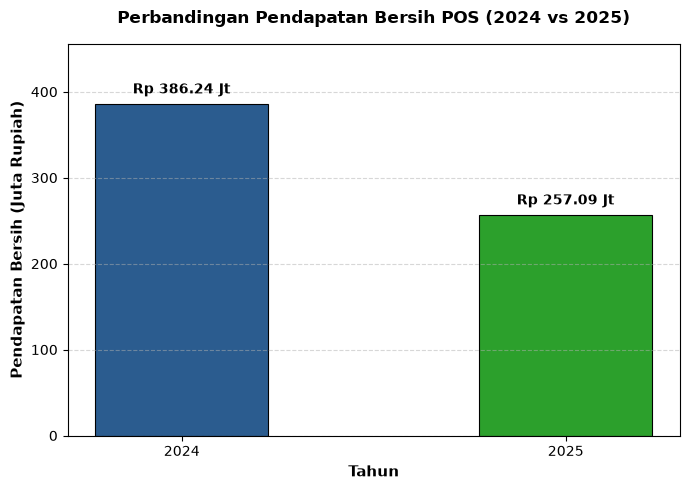

In [10]:
# Membuat grafik perbandingan pendapatan tahun 2024 vs 2025
plt.figure(figsize=(7, 5))

tahun_str = [str(int(t)) for t in rekap_pendapatan['tahun']]
nilai_miliar = rekap_pendapatan['pendapatan_bersih'] / 1_000_000  # Dalam satuan Juta Rupiah

bars = plt.bar(tahun_str, nilai_miliar, color=['#2b5c8f', '#2ca02c'], width=0.45, edgecolor='black', linewidth=0.8)

plt.title('Perbandingan Pendapatan Bersih POS (2024 vs 2025)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Tahun', fontsize=11, fontweight='bold')
plt.ylabel('Pendapatan Bersih (Juta Rupiah)', fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Menambahkan label nilai di atas setiap batang grafik
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 8, f'Rp {yval:,.2f} Jt', 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, max(nilai_miliar) * 1.18)
plt.tight_layout()
plt.show()


## 8. Ekspor Hasil Analisis ke Format CSV

Sesuai instruksi tugas, hasil analisis disimpan ke dalam file CSV:
1. `hasil_pendapatan_tahunan.csv`: Ringkasan pendapatan per tahun (2024 dan 2025).
2. `transaksi_pos_bersih.csv`: Dataset transaksi lengkap yang sudah bersih dan terhitung.


In [11]:
# 1. Simpan ringkasan pendapatan tahunan ke CSV
rekap_pendapatan.to_csv('hasil_pendapatan_tahunan.csv', index=False)
print("File 'hasil_pendapatan_tahunan.csv' berhasil disimpan.")

# 2. Simpan dataset transaksi bersih ke CSV
df.to_csv('transaksi_pos_bersih.csv', index=False)
print("File 'transaksi_pos_bersih.csv' berhasil disimpan.")


File 'hasil_pendapatan_tahunan.csv' berhasil disimpan.
File 'transaksi_pos_bersih.csv' berhasil disimpan.


## 9. Kesimpulan & Ringkasan Temuan

1. **Pembersihan Data**:
   - Ditemukan **30 baris data duplikat** yang berhasil dihapus sehingga dataset tersisa 5.000 baris transaksi unik.
   - Ditemukan **260 nilai kosong (*missing value*)** pada kolom `kode_kasir` yang ditangani dengan imputasi `'UNKNOWN'` tanpa menghilangkan data transaksi penjualan.
   - Format `harga_satuan` telah distandardisasi menjadi tipe data numerik (*float*), dan `tanggal` dikonversi menjadi `datetime`.

2. **Aturan Status dan Diskon**:
   - Transaksi dengan status `BATAL` (191 transaksi) dan `RETUR` (90 transaksi) telah disaring keluar dari perhitungan omset karena tidak merepresentasikan penjualan yang terealisasi.
   - Diskon persentase telah dipotongkan secara akurat dari nilai kotor penjualan.

3. **Hasil Pendapatan Riil**:
   - **Tahun 2024**: Rp 386.237.375,00 (dari 2.349 transaksi selesai).
   - **Tahun 2025**: Rp 257.085.100,00 (dari 2.370 transaksi selesai).
   - **Total Pendapatan Bersih**: Rp 643.322.475,00.
